In [1]:
import pandas as pd

prenoms = pd.read_csv("donnees/prenoms-2025-nat.csv", sep=";", keep_default_na=False)
prenoms["sexe"] = prenoms["sexe"].map({1: "garçon", 2: "fille"})

print(prenoms.shape)
print(prenoms.dtypes)
print("Années : ", prenoms["periode"].min(), "à", prenoms["periode"].max())
print("Valeurs manquantes :", prenoms.isna().sum().sum())
print(prenoms[prenoms["prenom"] == "NA"])

(724645, 5)
sexe       object
prenom     object
periode     int64
valeur      int64
rang        int64
dtype: object
Années :  1900 à 2025
Valeurs manquantes : 0
         sexe prenom  periode  valeur  rang
319660  fille     NA     2003       5  5405


In [2]:
#Question 1 : Quels sont les prénoms les plus données en 2025

In [3]:

annee_2025 = prenoms[prenoms["periode"] ==  2025]
for sexe in ["fille", "garçon"]:
    top = annee_2025[annee_2025["sexe"] == sexe].nlargest(5, "valeur")
    print(sexe, ":", ",".join(f"{p} ({v})" for p, v in zip(top["prenom"], top["valeur"])))

#

fille : LOUISE (3070),JADE (2925),AMBRE (2805),ALMA (2500),ALBA (2360)
garçon : GABRIEL (4625),NOAH (3465),LÉO (3420),RAPHAËL (3285),LOUIS (3260)


In [4]:
 #Question 2 : Des prénoms de plus en plus variés

In [5]:

par_annee = prenoms.groupby("periode").agg(naissances=("valeur", "sum"), prenom_differents=("prenom", "nunique"))

top10 = ( prenoms.sort_values("valeur", ascending=False)
         .groupby(["periode", "sexe"]).head(10)
         .groupby("periode")["valeur"].sum())
par_annee["part_top10_pct"] = (100* top10 / par_annee["naissances"]).round(1)

print(par_annee.loc[[1900, 1925, 1950, 1975, 2000]].to_string()) 

         naissances  prenom_differents  part_top10_pct
periode                                               
1900         412710               1617            43.4
1925         633100               2343            39.4
1950         881650               2632            37.8
1975         758230               5182            30.4
2000         777295               9200            18.1


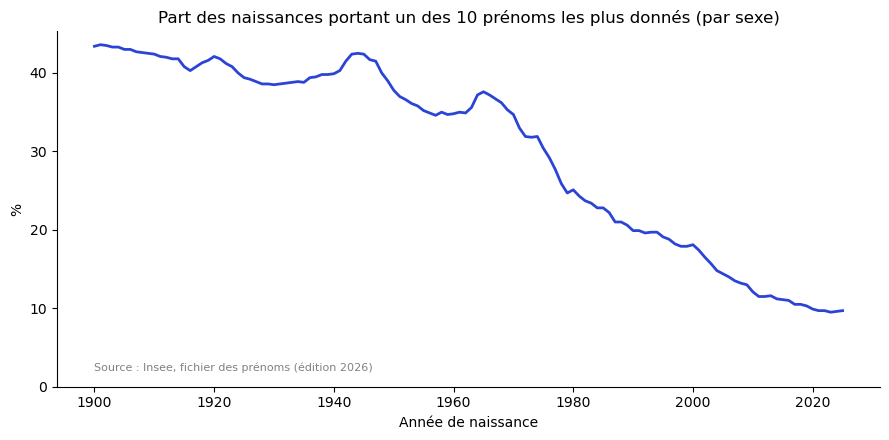

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt

Path("figures").mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(par_annee.index, par_annee["part_top10_pct"], color="#2B44D6", linewidth=2)
ax.set_title("Part des naissances portant un des 10 prénoms les plus donnés (par sexe)")
ax.set_xlabel("Année de naissance")
ax.set_ylabel("%")
ax.set_ylim(0, None)
ax.spines[["top", "right"]].set_visible(False)
ax.text(1900, 2, "Source : Insee, fichier des prénoms (édition 2026)", fontsize=8, color="gray")
fig.tight_layout()
fig.savefig("figures/part_top10.png", dpi=150)
plt.show()

In [7]:
#Question 3 : Quelle année certain prénom ont-ils atteint leur pic ?
choix = ["MARIE", "NATHALIE", "JULIE", "KEVIN", "EMMA", "GABRIEL", "LÉO"]
pics = (prenoms[prenoms["prenom"].isin(choix)]
        .sort_values("valeur", ascending=False)
        .drop_duplicates("prenom")[["prenom", "sexe", "periode", "valeur"]]
        .rename(columns={"periode": "annee_du_pic", "valeur" : "naissances_cette_annee"}))
print(pics.to_string(index=False))

  prenom   sexe  annee_du_pic  naissances_cette_annee
   MARIE  fille          1901                   52125
NATHALIE  fille          1966                   31410
   KEVIN garçon          1991                   13255
   JULIE  fille          1987                    9935
    EMMA  fille          2005                    7075
 GABRIEL garçon          2016                    5875
     LÉO garçon          2019                    4660


In [8]:

tableau = prenoms.pivot_table(index=["prenom", "sexe"], columns="periode", values="valeur", aggfunc="sum", fill_value=0)
evolution = tableau[[2015, 2025]].copy()
evolution = evolution[evolution[2025] >= 500]
evolution["multiplie_par"] = (evolution[2025] / evolution[2015]).round(1)
print(evolution.sort_values("multiplie_par", ascending=False).head(8).to_string())

periode        2015  2025  multiplie_par
prenom sexe                             
ESMÉE  fille     45  1530           34.0
IMRÂN  garçon    25   625           25.0
ZAYN   garçon    50  1245           24.9
ALBA   fille    110  2360           21.5
ALMA   fille    195  2500           12.8
KAYDEN garçon    75   865           11.5
AYLA   fille     65   665           10.2
RYM    fille     65   565            8.7


In [9]:
mixte = (annee_2025.pivot_table(index= "prenom", columns="sexe", values="valeur", aggfunc="sum", fill_value=0))

mixte["total"] = mixte["fille"] + mixte["garçon"]
mixte["part_filles_pct"] = (100 *  mixte["fille"] / mixte["total"]).round(0)
resultat = mixte[(mixte["total"] >= 200) & mixte["part_filles_pct"].between(30, 70)]
print(resultat.sort_values("total", ascending=False).to_string())

sexe     fille  garçon  total  part_filles_pct
prenom                                        
CHARLIE   1715    1050   2765             62.0
CAMILLE    640     915   1555             41.0
ANDRÉA     515     700   1215             42.0
NOA        320     715   1035             31.0
SASHA      315     460    775             41.0
LOUISON    340     310    650             52.0
LAYAN      135      80    215             63.0
ADAMA       60     140    200             30.0


In [10]:
prenoms["decennie"] = prenoms["periode"]//10*10
prenoms["lettres_x_naissances"] = prenoms["prenom"].str.len() * prenoms["valeur"]
prenoms["naissances_compose"] = prenoms["valeur"].where(prenoms["prenom"].str.contains("-"), 0)

par_decennie = prenoms.groupby("decennie")[["valeur", "lettres_x_naissances", "naissances_compose"]].sum()
par_decennie["longueur_moyenne"] = (par_decennie["lettres_x_naissances"] / par_decennie["valeur"]).round(2)
par_decennie["pct_composes"] = (100 * par_decennie["naissances_compose"] / par_decennie["valeur"]).round(1)
print(par_decennie[["longueur_moyenne", "pct_composes"]].to_string())

          longueur_moyenne  pct_composes
decennie                                
1900                  6.30           0.7
1910                  6.30           0.7
1920                  6.33           0.7
1930                  6.41           1.3
1940                  6.67           5.9
1950                  7.01           9.2
1960                  7.11           7.1
1970                  7.01           3.6
1980                  6.68           2.4
1990                  6.32           1.4
2000                  5.76           0.9
2010                  5.50           0.6
2020                  5.41           0.4


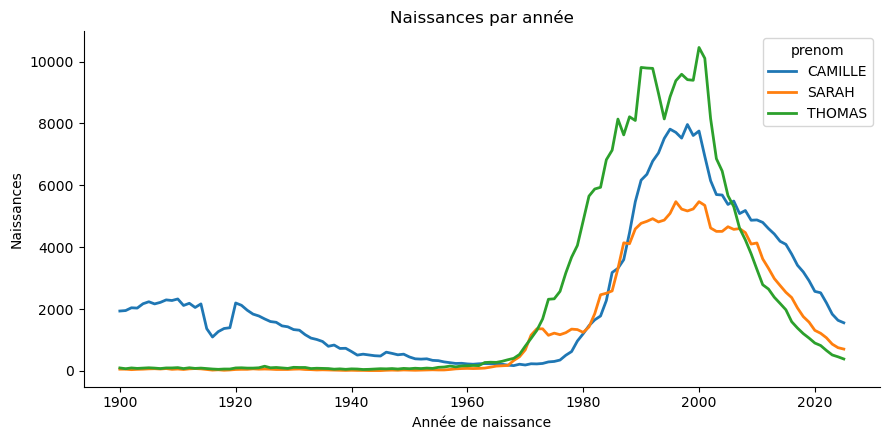

prenom
CAMILLE    1998
SARAH      1996
THOMAS     2000
dtype: int64


In [11]:
mes_prenoms = ["CAMILLE", "THOMAS", "SARAH"]   

courbes = (prenoms[prenoms["prenom"].isin(mes_prenoms)]
           .groupby(["periode", "prenom"])["valeur"].sum()   
           .unstack(fill_value=0))

fig, ax = plt.subplots(figsize=(9, 4.5))
courbes.plot(ax=ax, linewidth=2)
ax.set_title("Naissances par année")
ax.set_xlabel("Année de naissance")
ax.set_ylabel("Naissances")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("figures/mes_prenoms.png", dpi=150)
plt.show()
print(courbes.idxmax())